## EDA: Exploración de la estructura relacional (P2)

Se explora la **forma de la red** sobre `data/staging/`: decide qué técnicas escalan, qué umbrales usar y qué grafo
construir. Se usan ids crudos a propósito, para que el KDD muestre cuánto cambia la red tras la resolución de entidades

### Imports

In [1]:
import os, socket, time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.sql.types import ArrayType, StructType

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 80)

### Utilidades

- Constantes

In [2]:
NOTEBOOK = "b_exploracion"

proyecto = Path.cwd()
while not (proyecto / "docker-compose.yml").exists() and proyecto != proyecto.parent:
    proyecto = proyecto.parent

raw_dir     = proyecto / "data" / "raw"
bronze_dir  = proyecto / "data" / "bronze"
staging_dir = proyecto / "data" / "staging"
final_dir   = proyecto / "data" / "final"
artef_dir   = proyecto / "data" / "artefactos"
tc_path     = proyecto / "data" / "cambios.csv"
anios = [2023, 2024, 2025]

out_dir = proyecto / "01_EDA_KDD" / "temp" / NOTEBOOK
fig_dir, tab_dir, web_dir = out_dir / "figs", out_dir / "tablas", out_dir / "web"
for d in (fig_dir, tab_dir, web_dir):
    d.mkdir(parents=True, exist_ok=True)

def mostrar_fig(nombre):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def guardar_tabla(df, nombre):
    sdf = spark.createDataFrame(df) if isinstance(df, pd.DataFrame) else df
    sdf.coalesce(1).write.mode("overwrite").parquet(str(tab_dir / nombre))
    sdf.toPandas().to_json(web_dir / f"{nombre}.json", orient="records", force_ascii=False, date_format="iso", indent=1)
    return len(df) if isinstance(df, pd.DataFrame) else sdf.count()

def leer(directorio, nombre):
    return spark.read.parquet(str(directorio / nombre))

- Spark

In [3]:
spark_master = os.environ.get("spark_master", "local[*]")

builder = (SparkSession.builder
           .appName(NOTEBOOK)
           .master(spark_master)
           .config("spark.driver.memory",   os.environ.get("SPARK_DRIVER_MEMORY", "4g"))
           .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "4g"))
           .config("spark.sql.shuffle.partitions", "24")
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "America/Lima"))

if spark_master.startswith("spark://"):
    builder = (builder.config("spark.driver.host", socket.gethostname())
                      .config("spark.driver.bindAddress", "0.0.0.0"))

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
SHUFFLE = int(spark.conf.get("spark.sql.shuffle.partitions"))

### Verificación del cluster

In [4]:
sc = spark.sparkContext
estado = sc._jsc.sc().getExecutorMemoryStatus()

print(f"Master        : {sc.master}")
print(f"Executors     : {estado.size() - 1}")
print(f"Cores totales : {sc.defaultParallelism}")
print(f"Memoria driver: {sc._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3:.1f} GB")
print("UI del job    : http://localhost:4040")

Master        : spark://spark-master:7077
Executors     : 0
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

In [5]:
proc  = leer(staging_dir, "procesos").where(F.col("anio").isin(anios)).cache()
adj   = leer(staging_dir, "adjudicaciones").where(F.col("anio").isin(anios) & F.col("proveedor_id_raw").isNotNull()).cache()
of    = leer(staging_dir, "oferentes").where(F.col("anio").isin(anios) & F.col("oferente_id_raw").isNotNull()).cache()
items = leer(staging_dir, "items").where(F.col("anio").isin(anios))
print(f"procesos {proc.count():,} | filas adj {adj.count():,} | filas oferentes {of.count():,}")

procesos 235,977 | filas adj 199,413 | filas oferentes 2,907,384


---
### 1. Bipartito entidad–proveedor: tamaño, densidad y grados

Entidades 2,992 | Proveedores 86,027 | Aristas 136,117 | Densidad 0.05288%


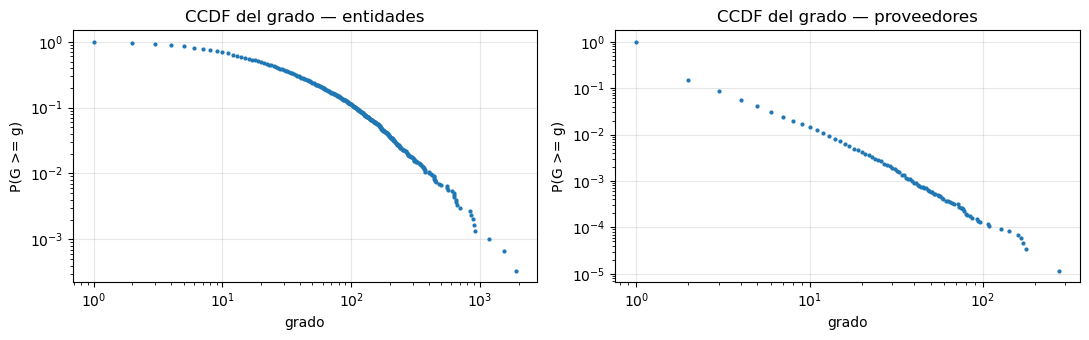

Proveedores con una sola entidad: 84.9%


In [6]:
aristas = (adj.join(proc.select("ocid", "entidad_id_raw"), "ocid")
              .groupBy("entidad_id_raw", "proveedor_id_raw")
              .agg(F.count("*").alias("n_adj"), F.sum("monto_adj").alias("monto"))).cache()
n_e = aristas.select("entidad_id_raw").distinct().count()
n_p = aristas.select("proveedor_id_raw").distinct().count()
n_a = aristas.count()
densidad = n_a / (n_e * n_p)
print(f"Entidades {n_e:,} | Proveedores {n_p:,} | Aristas {n_a:,} | Densidad {densidad:.5%}")

grado_e = aristas.groupBy("entidad_id_raw").agg(F.count("*").alias("grado"))
grado_p = aristas.groupBy("proveedor_id_raw").agg(F.count("*").alias("grado"))
dist = {"entidades": grado_e.groupBy("grado").count().toPandas(),
        "proveedores": grado_p.groupBy("grado").count().toPandas()}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for i, (k, d) in enumerate(dist.items()):
    d = d.sort_values("grado")
    ccdf = (d["count"][::-1].cumsum()[::-1]) / d["count"].sum()
    ax[i].loglog(d["grado"].values, ccdf.values, ".", ms=4)
    ax[i].set_title(f"CCDF del grado — {k}"); ax[i].set_xlabel("grado"); ax[i].set_ylabel("P(G >= g)")
mostrar_fig("grado_ccdf")

pct_p_grado1 = grado_p.where("grado = 1").count() / n_p
print(f"Proveedores con una sola entidad: {pct_p_grado1:.1%}")

- Densidad ‹d›: la matriz entidad × proveedor es extremadamente dispersa → se guarda en formato largo (COO). Esto
  favorece factores latentes (ALS implícito) sobre vecindario puro, porque con poco solapamiento la similitud es ruidosa
- Si la CCDF es aproximadamente recta en log-log, el grado tiene cola pesada: pocos actores concentran las conexiones, y
  ahí PageRank/HITS sí discriminan
- ‹pct_p_grado1›% de proveedores con grado 1: son hojas, aportan poco a comunidades y se podan en el subgrafo de los
  métodos exactos

### 2. Oferentes por proceso → costo del grafo de co-participación

oferentes por proceso (p50, p90, p99, p99.9): [9.0, 31.0, 74.0, 341.0]
procesos con oferentes listados: 214,842 de 235,977
listados == numberOfTenderers: 0.9768248294095195
filas duplicadas dentro del proceso: 0


,pares_todos,pares_hasta_10,pares_hasta_30,pares_hasta_50
0,44271475.0,1438280.0,13096295.0,24208281.0


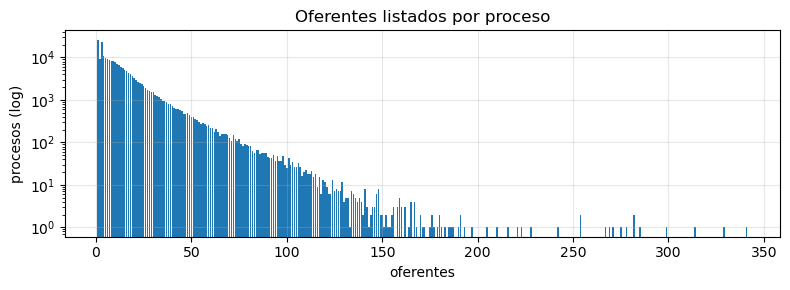

In [7]:
n_of = (of.groupBy("ocid").agg(F.countDistinct("oferente_id_raw").alias("n_listados"), F.count("*").alias("n_filas"))
          .join(proc.select("ocid", "n_postores"), "ocid", "left")).cache()
q_of = n_of.approxQuantile("n_listados", [.5, .9, .99, .999], .001)
print("oferentes por proceso (p50, p90, p99, p99.9):", q_of)
print(f"procesos con oferentes listados: {n_of.count():,} de {proc.count():,}")
print(f"listados == numberOfTenderers: {n_of.select(F.avg((F.col('n_listados') == F.col('n_postores')).cast('int'))).first()[0]}")
print(f"filas duplicadas dentro del proceso: {n_of.select(F.sum(F.col('n_filas') - F.col('n_listados'))).first()[0]}")

par = F.col("n_listados") * (F.col("n_listados") - 1) / 2
costo_pares = n_of.select(F.sum(par).alias("pares_todos"),
                          *[F.sum(F.when(F.col("n_listados") <= c, par)).alias(f"pares_hasta_{c}") for c in (10, 30, 50)]).toPandas()
display(costo_pares)

h = n_of.groupBy("n_listados").count().orderBy("n_listados").toPandas()
plt.figure(figsize=(8, 3)); plt.bar(h.n_listados, h["count"]); plt.yscale("log")
plt.title("Oferentes listados por proceso"); plt.xlabel("oferentes"); plt.ylabel("procesos (log)")
mostrar_fig("oferentes_por_proceso")

- Un proceso con n oferentes genera n(n−1)/2 pares: los procesos masivos dominan el conteo aunque sean pocos. Con tope en
  ‹p99› se conserva el ‹x›% de los pares informativos
- Competir en un proceso de 40 postores dice menos de un vínculo que competir en uno de 3 → peso Σ 1/(n−1) (ponderación
  de Newman para redes de colaboración)

### 3. Tasa de éxito y ganadores no listados como oferentes

In [8]:
part = of.select("ocid", F.col("oferente_id_raw").alias("id")).distinct().withColumn("oferto", F.lit(1))
gana = adj.select("ocid", F.col("proveedor_id_raw").alias("id")).distinct().withColumn("gano", F.lit(1))
exito = part.join(gana, ["ocid", "id"], "full").fillna(0, ["oferto", "gano"])
resumen_exito = exito.agg(F.sum("oferto").alias("participaciones"),
                          F.sum(F.col("oferto") * F.col("gano")).alias("ganadas_listadas"),
                          F.sum(((F.col("oferto") == 0) & (F.col("gano") == 1)).cast("int")).alias("ganadas_no_listadas")).toPandas()
display(resumen_exito)
por_prov = exito.groupBy("id").agg(F.sum("oferto").alias("ofertas"), F.sum(F.col("oferto") * F.col("gano")).alias("ganadas"))
print("tasa de éxito (>=5 ofertas) p10/p50/p90:",
      por_prov.where("ofertas >= 5").withColumn("t", F.col("ganadas") / F.col("ofertas")).approxQuantile("t", [.1, .5, .9], .01))

,participaciones,ganadas_listadas,ganadas_no_listadas
0,2907384,199237,23


tasa de éxito (>=5 ofertas) p10/p50/p90: [0.0, 0.0, 0.25]


- Las ganadas **no listadas** corresponden sobre todo a contratación directa o régimen especial. En el KDD los ganadores
  se agregan a los participantes del proceso para no perder nodos
- La tasa de éxito es una feature natural del vector de proveedor (Parte II)

### 4. Multi-pertenencia (región y segmento UNSPSC)

In [9]:
seg = items.where("unspsc IS NOT NULL").select("ocid", F.substring("unspsc", 1, 2).alias("segmento")).distinct()
cobertura = seg.select("ocid").distinct().count() / proc.count()
mp = (adj.select("ocid", "proveedor_id_raw").distinct()
         .join(proc.select("ocid", "region"), "ocid").join(seg, "ocid", "left")
         .groupBy("proveedor_id_raw").agg(F.countDistinct("region").alias("n_regiones"),
                                          F.countDistinct("segmento").alias("n_segmentos")))
multi = mp.agg(F.avg((F.col("n_regiones") > 1).cast("int")).alias("pct_multi_region"),
               F.avg((F.col("n_segmentos") > 1).cast("int")).alias("pct_multi_segmento")).toPandas()
print(f"procesos con al menos un UNSPSC: {cobertura:.1%}"); display(multi)

procesos con al menos un UNSPSC: 84.6%


,pct_multi_region,pct_multi_segmento
0,0.109501,0.099271


- Si ‹pct_multi_region› o ‹pct_multi_segmento› es alto, un proveedor vive en varios mercados a la vez → AGM/BigCLAM
  (comunidades solapadas) además de una partición dura

### 5. Concentración por entidad (HHI sobre monto adjudicado)

HHI p25/p50/p75/p90: [0.07932386510971604, 0.16724567592675263, 0.3391207795948195, 0.568289606616373]
entidades con HHI > 0.25 (alta concentración): 36.8%


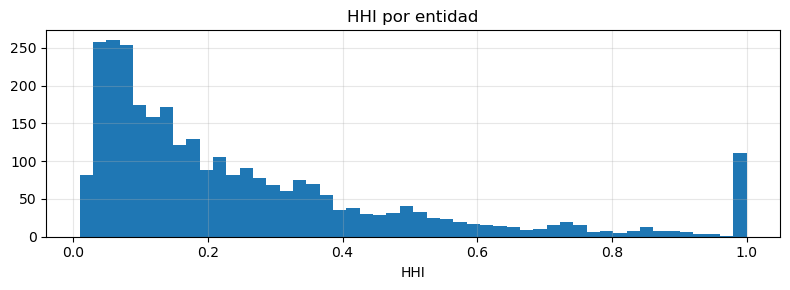

In [10]:
w = Window.partitionBy("entidad_id_raw")
hhi = (aristas.where("monto > 0").withColumn("s", F.col("monto") / F.sum("monto").over(w))
       .groupBy("entidad_id_raw").agg(F.sum(F.col("s") ** 2).alias("hhi"), F.max("s").alias("share_top"),
                                      F.count("*").alias("n_prov")))
q_hhi = hhi.approxQuantile("hhi", [.25, .5, .75, .9], .01)
pct_hhi_alto = hhi.where("hhi > 0.25").count() / hhi.count()
print("HHI p25/p50/p75/p90:", q_hhi)
print(f"entidades con HHI > 0.25 (alta concentración): {pct_hhi_alto:.1%}")
hh = hhi.select("hhi").toPandas()
plt.figure(figsize=(8, 3)); plt.hist(hh.hhi, bins=50); plt.title("HHI por entidad"); plt.xlabel("HHI")
mostrar_fig("hhi_entidades")

### 6. Pares que co-participan seguido (tope 30 oferentes)

In [11]:
of_cap = (of.dropDuplicates(["ocid", "oferente_id_raw"])
            .join(n_of.where("n_listados BETWEEN 2 AND 30").select("ocid"), "ocid"))
top_pares = (of_cap.alias("a").join(of_cap.alias("b"),
                 (F.col("a.ocid") == F.col("b.ocid")) & (F.col("a.oferente_id_raw") < F.col("b.oferente_id_raw")))
             .groupBy(F.col("a.oferente_id_raw").alias("id_a"), F.col("b.oferente_id_raw").alias("id_b"))
             .agg(F.first("a.oferente").alias("oferente_a"), F.first("b.oferente").alias("oferente_b"),
                  F.count("*").alias("procesos_juntos"))
             .orderBy(F.desc("procesos_juntos")))
top_pares.show(10, truncate=35)

+------------------+------------------+-----------------------------------+-----------------------------------+---------------+
|              id_a|              id_b|                         oferente_a|                         oferente_b|procesos_juntos|
+------------------+------------------+-----------------------------------+-----------------------------------+---------------+
|PE-RUC-20274419637|PE-RUC-20603425104|J.C.A. CONTRATISTAS GENERALES S....|TECNICAS DE INGENIERIA Y CONTRAT...|           1510|
|PE-RUC-20541777980|PE-RUC-20569118124|GRUPO 3A CONSULTORIA & CONSTRUCC...|                JATUN SACHA E.I.R.L|           1493|
|PE-RUC-20533943706|PE-RUC-20542059291|CORPORACION INTERNACIONAL RIO AM...|     CORPORACION GRUPO IBIZA S.A.C.|           1355|
|PE-RUC-20603425104|PE-RUC-20608231685|TECNICAS DE INGENIERIA Y CONTRAT...|            CRG INGENIEROS E.I.R.L.|           1319|
|PE-RUC-20605753907|PE-RUC-20612573621|INVERSIONES GENERALES LAURA ROCA...|           CONSTRUCAPRIGLE E.

- Pares que compiten juntos cientos de veces son la materia prima de las comunidades. Es una **señal descriptiva** de
  mercado (mismo rubro o región); la colusión requeriría revisar ganadores alternados o precios

### 7. Escritura de resultados

In [12]:
tablas = {"resumen_bipartito": pd.DataFrame([{"entidades": n_e, "proveedores": n_p, "aristas": n_a,
                                              "densidad": densidad, "pct_prov_grado1": pct_p_grado1}]),
          "grado_entidades": dist["entidades"], "grado_proveedores": dist["proveedores"],
          "oferentes_cuantiles": pd.DataFrame([dict(zip(["p50", "p90", "p99", "p999"], q_of))]),
          "costo_pares": costo_pares, "exito": resumen_exito, "multi_pertenencia": multi,
          "hhi_resumen": pd.DataFrame([dict(zip(["p25", "p50", "p75", "p90"], q_hhi), pct_hhi_alto=pct_hhi_alto)]),
          "top_pares_coparticipacion": top_pares.limit(50)}
escritos = {nombre: guardar_tabla(df, nombre) for nombre, df in tablas.items()}
print(f"Escrito en 01_EDA_KDD/temp/{NOTEBOOK}/: {', '.join(escritos)}")

Escrito en 01_EDA_KDD/temp/b_exploracion/: resumen_bipartito, grado_entidades, grado_proveedores, oferentes_cuantiles, costo_pares, exito, multi_pertenencia, hhi_resumen, top_pares_coparticipacion


#### a. Verificación

In [13]:
for nombre, n in escritos.items():
    leido = spark.read.parquet(str(tab_dir / nombre)).count()
    assert leido == n, f"{nombre}: esperaba {n}, leí {leido}"
    assert (web_dir / f"{nombre}.json").exists(), f"falta web/{nombre}.json"

figs = sorted(p.stem for p in fig_dir.glob("*.png"))
print(f"OK: {len(escritos)} tablas (parquet + json)" + (f" | {len(figs)} figuras: {', '.join(figs)}" if figs else ""))

OK: 9 tablas (parquet + json) | 3 figuras: grado_ccdf, hhi_entidades, oferentes_por_proceso


---
### 8. Cerrar sesión

In [14]:
spark.stop()